In [6]:
import pandas as pd
import numpy as np
from shap import TreeExplainer
from shap.plots import violin,waterfall,bar,beeswarm,scatter
import matplotlib.pyplot as plt
import joblib
from pathlib import Path

parent_dir = Path().resolve().parent

In [7]:
X_test_path = parent_dir / "XandYDataframes\X_test_Dataframe.csv"
X_test = pd.read_csv(X_test_path)
DropColumn = list(X_test.columns)
X_test = X_test.drop(columns=DropColumn[0])

X_train_path = parent_dir / "XandYDataframes\X_train_Dataframe.csv" 
X_train = pd.read_csv(X_train_path)
X_train = X_train.drop(columns=DropColumn[0])

Y_test_path = parent_dir / "XandYDataframes\Y_test_Dataframe.csv" 
Y_test = pd.read_csv(Y_test_path)
Y_test = Y_test.drop(columns=DropColumn[0])

Y_train_path = parent_dir / "XandYDataframes\Y_train_Dataframe.csv"
Y_train = pd.read_csv(Y_train_path)
Y_train = Y_train.drop(columns=DropColumn[0])

X_Predict_path = parent_dir / "XandYDataframes\X_Predict_Dataframe.csv"
X_Predict = pd.read_csv(X_Predict_path)
X_Predict = X_Predict.drop(columns=(list(X_Predict.columns))[0])

In [8]:
XGBoostPipeline = joblib.load("XGBoostPipeline.pkl")

In [9]:
Model = XGBoostPipeline.named_steps['xgboost']
SubXGBoostPipeline = XGBoostPipeline[:2] #this accesses only the first two steps of the pipeline
X_test_transformed = SubXGBoostPipeline.transform(X_test)
FeatureNames = SubXGBoostPipeline.get_feature_names_out()

X_test_dataframe = pd.DataFrame(X_test_transformed,columns=FeatureNames)

explainer = TreeExplainer(Model)
shap_values = explainer(X_test_dataframe)

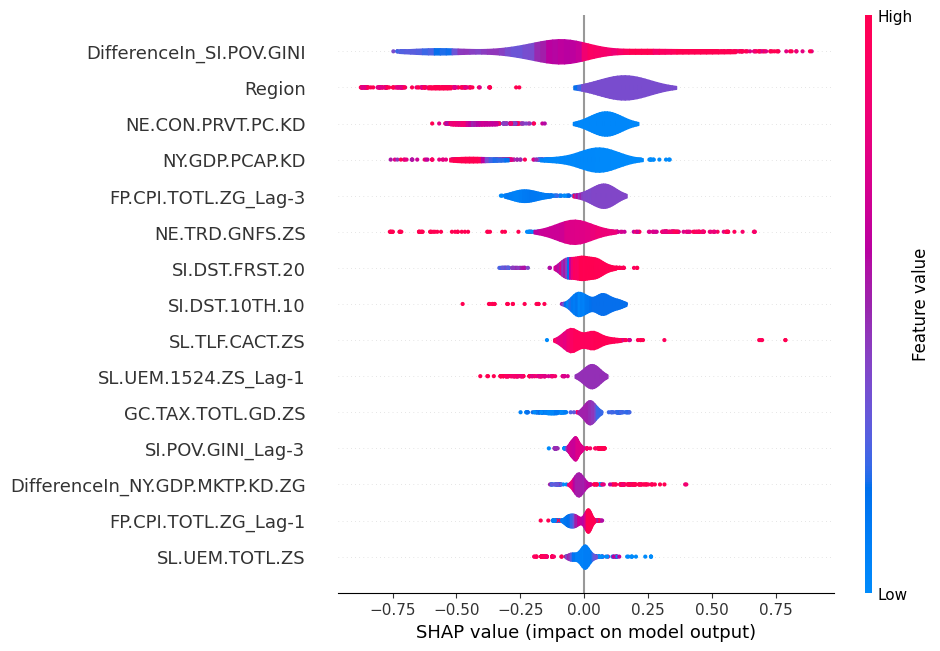

In [10]:
violin(shap_values,
       feature_names=FeatureNames,
       max_display=15)

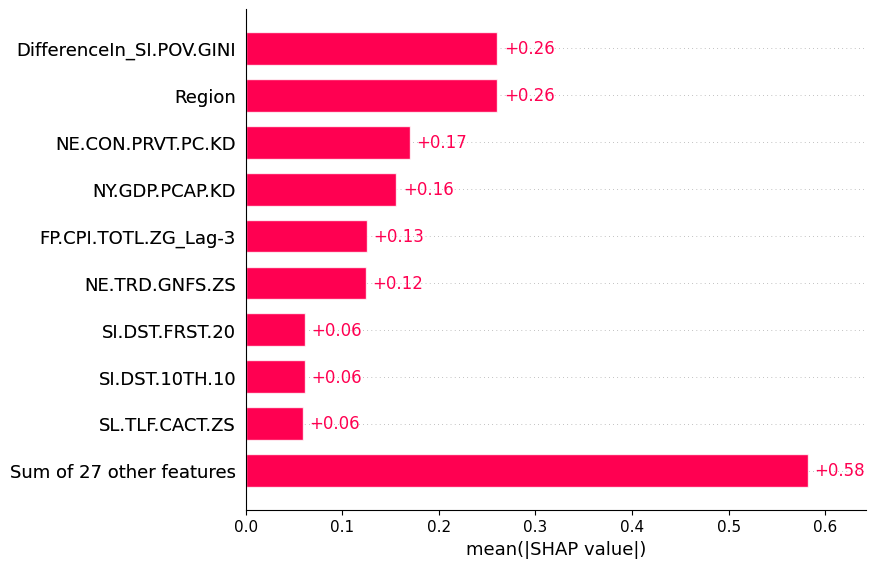

In [11]:
bar(shap_values)
#using shap.plots.bar

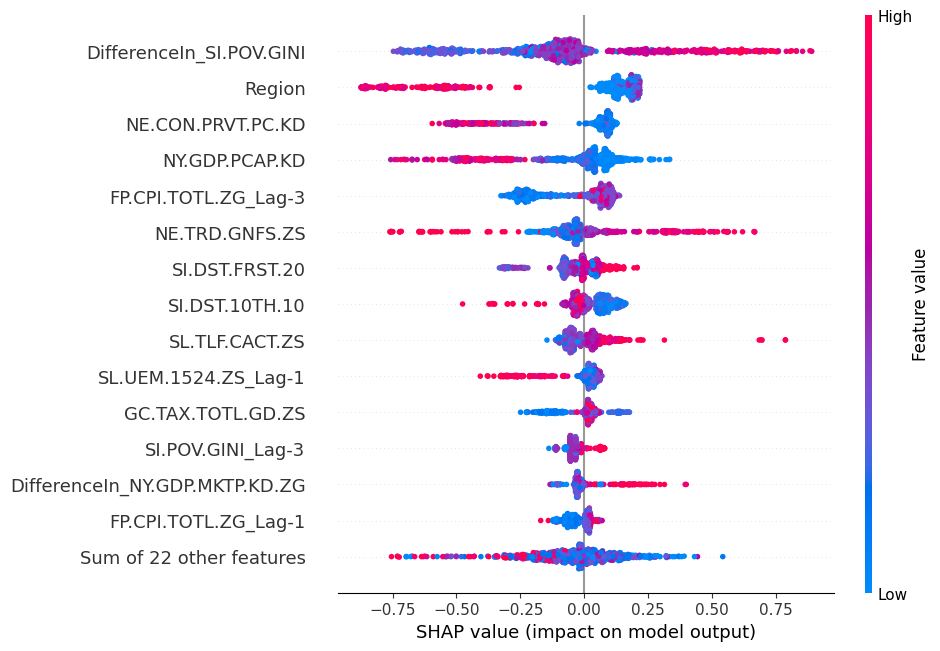

In [12]:
beeswarm(shap_values,
         max_display = 15)

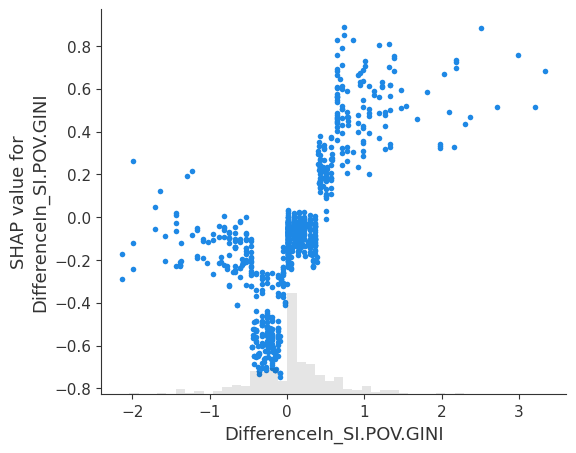

In [13]:
scatter(shap_values[:,"DifferenceIn_SI.POV.GINI"])


In [14]:
Model = XGBoostPipeline.named_steps['xgboost']
SubXGBoostPipeline = XGBoostPipeline[:2] #this accesses only the first two steps of the pipeline
X_Predict_transformed = SubXGBoostPipeline.transform(X_Predict)
PredictFeatureNames = SubXGBoostPipeline.get_feature_names_out()

X_Predict_dataframe = pd.DataFrame(X_Predict_transformed,columns=FeatureNames)

explainer = TreeExplainer(Model)
predict_shap_values = explainer(X_Predict_dataframe)

In [15]:
#find where the the UK is in x_train, gen shapley values for it and then pass to waterfall
#locate -> generate -> plot
FeatureEngineeredDataframe = pd.read_csv("FeatureEngineeredDataFrame.csv")
DroppedColumn = FeatureEngineeredDataframe.columns
FeatureEngineeredDataframe = FeatureEngineeredDataframe.drop(columns=DroppedColumn[0])

GBRDataFrame = pd.DataFrame(FeatureEngineeredDataframe.where(FeatureEngineeredDataframe['countryiso3code']=='GBR'))
GBRDataFrame = GBRDataFrame.dropna(axis=0,how='all')

#row index of where the GBR date value is 2015
Index = GBRDataFrame.index[GBRDataFrame['date']==float(2015)]
RowToFind = GBRDataFrame.loc[Index]
ColumnsToNotKeep = [col for col in RowToFind.columns if col not in DropColumn] 

In [16]:
RowToFind = RowToFind.drop(columns=ColumnsToNotKeep)

In [17]:
RegionNames =list(FeatureEngineeredDataframe.value_counts('Region').index)
SubstituteNames = {}
for i,j in enumerate(RegionNames):
    SubstituteNames[j] = i

RowToFind['Region'] = RowToFind['Region'].map(SubstituteNames)

In [18]:
#need to locate where inside of X Train is RowToFind
TargetSeries = RowToFind.iloc[0] #convert into a series
TargetIndex = X_test[(X_test == TargetSeries).all(axis=1)].index
TargetIndex = TargetIndex.start #got the location

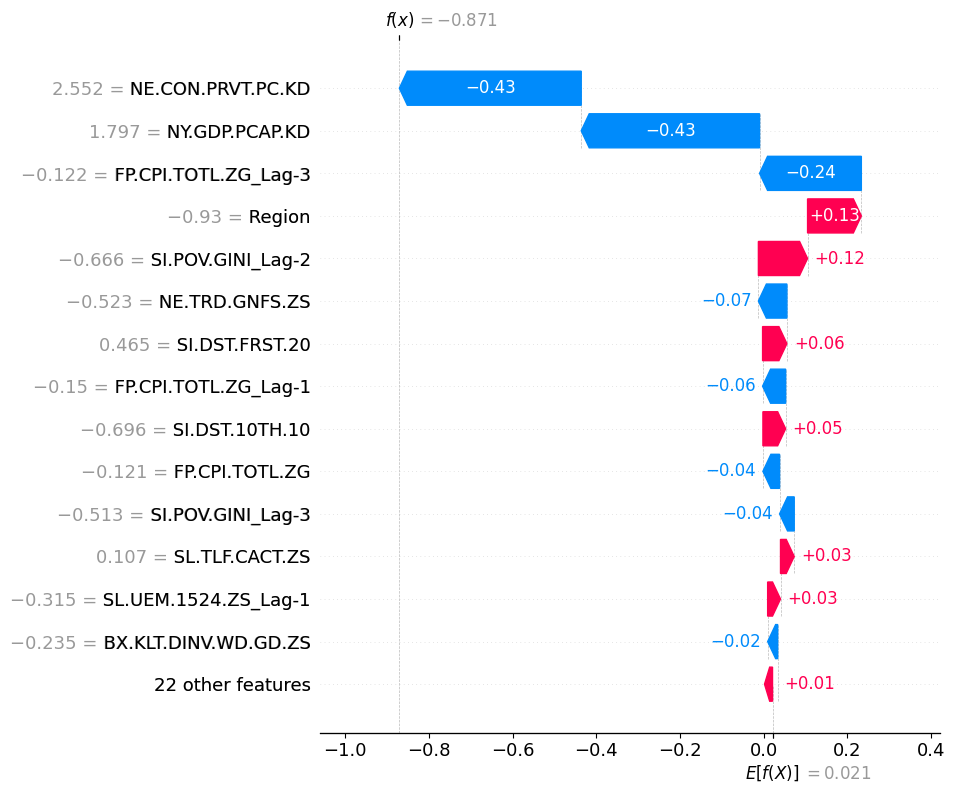

In [19]:
waterfall(shap_values[TargetIndex],max_display=15)

In [20]:
ShapValues_path = parent_dir / 'dashboard/assets/ShapValues' 
NumpyArrayShapValues = np.array(shap_values.values)
np.save(ShapValues_path,NumpyArrayShapValues)

PredictShapValues_path = parent_dir / 'dashboard/assets/PredictShapValues'
PredictNumpyArrayShapValues = np.array(predict_shap_values.values)
np.save(PredictShapValues_path , PredictNumpyArrayShapValues)

BasePredictShap_path = parent_dir / 'dashboard/assets/PredictShapValuesBaseValues.csv'
PredictShapValuesBaseValues = pd.DataFrame(predict_shap_values.base_values)
PredictShapValuesBaseValues.to_csv(BasePredictShap_path)

DataPredictShap_path = parent_dir / 'dashboard/assets/PredictShapValuesData.csv'
PredictShapValuesData = pd.DataFrame(predict_shap_values.data)
PredictShapValuesData.to_csv(DataPredictShap_path)

PredictShapNames_path = parent_dir / 'dashboard/assets/PredictShapValuesFeatureNames.csv'
PredictShapValuesFeatureNames = pd.DataFrame(predict_shap_values.feature_names)
PredictShapValuesFeatureNames.to_csv(PredictShapNames_path)
#saving everything as is to preserve the order so i can call it easy